# A Neural Probabilistic Language Model

=> I am reading this as part of makemorev2 (MLP implementation) pre-req, and by the title and the abstract, I understand that this new language model is an improvement over the existing n-gram models back in 2003. It talks about limitations of n-gram models such as lower context limit and increasing the number of n's on n-gram for more context resulting in impossible number of calculations due to curse of dimensionality. 

Also, the n-gram models treat words as an isolated symbol without preserving any relationships between the words, which limits n-gram models to only assign higher probability for combinations it has already seen. So if it was trained on the text "cat ran away", that would not give it the ability to predict the text "dog ran away". 

And there are many many combinations of words in the english language that will make it impossible to run it entirely through the model. 

For instance, if we imagine a sentence consisting of 10 words, and say for simplicity that there are around 100,000 english words (there are way more than that), so if we try and observe the number of possible combinations of words in that sentence that'd be:

100,000 * 100,000 * 100,000 * 100,000 ..... 100,000  } 10 times
i.e.

$(10^5)^{10} => 10^{50} \quad possible \ combinations$

that is a lot of combinations.

That is what this paper is trying to solve with a different better approach.

In [7]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [8]:
words = open('names.txt', 'r').read().splitlines()
words[:2]

['emma', 'olivia']

In [12]:
chars = sorted(list(set("".join(words))))
len(chars)

26

In [46]:
stoi = {a:i+1 for i, a in enumerate(chars)}
stoi["."] = 0
itos = {i:s for s, i in stoi.items()}

In [203]:
# block_size = 3
# # as the paper does, its the context length, the number of chars we take to predict the next
# X, Y = [], []

# for w in words:
#     context = [0] * block_size
#     for ch in w + '.':
#         ix = stoi[ch]
#         X.append(context)
#         Y.append(ix)
#         # print(''.join(itos[i] for i in context), '->', itos[ix])
#         context = context[1:] + [ix]

# X = torch.tensor(X)
# Y = torch.tensor(Y)

In [26]:
# blockasdasdfasdf = 3
# [0] * blockasdasdfasdf

[0, 0, 0]

In [204]:
# X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [455]:
def build_dataset(words):
    block_size = 4
    X, Y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '->', itos[ix])
            context = context[1:] + [ix]
    
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[n2:])

torch.Size([182580, 4]) torch.Size([182580])
torch.Size([22767, 4]) torch.Size([22767])
torch.Size([22799, 4]) torch.Size([22799])


In [51]:
# Lookup table
# --> The paper uses 30 dimension for the lookup table for 17k vocabulary, since 
# in our case, we are buildling a charcter level language model, we have 27 vocab
# requiring far fewer dimensions, say 2.

# features := 2

# we start with random values, which later after training gets updated, such that
# frequently occuring characters stay near to each other in the vector space.



C = torch.randn((27, 2)) # 27 vocab size, 2 is the dimension

In [53]:
C[5]

tensor([ 1.4573, -0.5313])

In [72]:
# F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([ 1.4573, -0.5313])

In [78]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [79]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [110]:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], -1).shape

torch.Size([32, 6])

In [119]:
# emb.view(32, 6).shape

torch.Size([32, 6])

In [132]:
# torch.unbind(emb, 1)[0].shape

torch.Size([32, 2])

In [123]:
# torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([32, 6])

In [153]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

In [154]:
h

tensor([[ 0.9351, -0.9869,  0.9983,  ...,  0.9317, -0.9329,  0.9779],
        [ 0.7064, -0.9769,  0.9966,  ...,  0.9810, -0.8963,  0.9828],
        [ 0.8249, -1.0000,  1.0000,  ..., -0.9206, -0.9998,  0.9987],
        ...,
        [ 1.0000,  0.9999, -0.8101,  ...,  0.9998,  0.9677,  0.4902],
        [ 0.8373,  0.9801,  0.3541,  ..., -0.8486,  0.7080, -0.1692],
        [ 0.3967,  0.9997, -0.8870,  ...,  0.9896,  0.9889, -0.9864]])

In [155]:
h.shape

torch.Size([32, 100])

In [157]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [158]:
logits = h @ W2 + b2

In [161]:
logits.shape

torch.Size([32, 27])

In [163]:
counts = logits.exp()

In [164]:
prob = counts / counts.sum(1, keepdims=True)

In [167]:
prob.shape

torch.Size([32, 27])

In [169]:
loss = -prob[torch.arange(32), Y].log().mean()

In [170]:
loss

tensor(14.0650)

### Organized Steps

In [456]:
print("Dataset")
Xtr.shape, Ytr.shape

Dataset


(torch.Size([182580, 4]), torch.Size([182580]))

In [457]:
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((27, 10), generator=g)
W1 = torch.randn((40, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [458]:
print("Total number of params: ")
sum(p.nelement() for p in parameters)

Total number of params: 


13897

In [459]:
for p in parameters:
    p.requires_grad = True

In [460]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [461]:
lri = []
lossi = []
stepi = []

#### Forward and Backward Pass

In [ ]:

for i in range(100000):

    # minibatching
    ix = torch.randint(0, Xtr.shape[0], (60, ))
    
    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 40) @ W1 + b1)
    logits = h @ W2 + b2
    # counts = logits.exp()
    # prob = counts/counts.sum(1, keepdim=True)
    # loss = -prob[torch.arange(32), Y].log().mean()
    loss = F.cross_entropy(logits, Ytr[ix])
    # print(loss.item())
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.01
    for p in parameters:
        p.data += -lr* p.grad

    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())
    
print("Final Loss: ", loss.item())

In [ ]:
plt.plot(stepi, lossi)

In [ ]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

In [ ]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

In [489]:
# training split(80%), dev/validation split(10%), test split(10%)

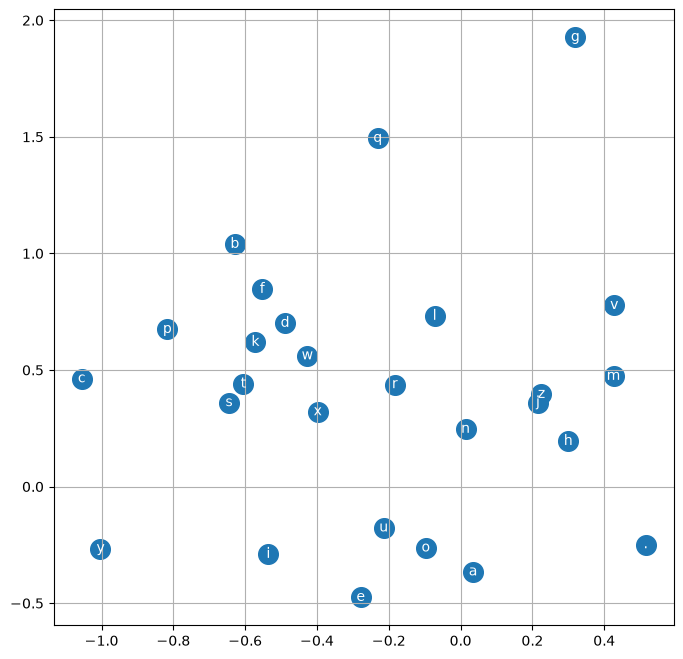

In [388]:
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], ha="center", va="center", color="white")
plt.grid('minor')

In [ ]:
# sampling

g = torch.Generator().manual_seed(2147483647)
block_size = 4
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        # ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        ix = torch.multinomial(probs, num_samples=1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))